# Quick-Commerce Delivery Intelligence — CBIM Problem Canvas

**Goal:** Analyse delivery data, predict delivery time and late-order risk, identify high-demand geographical zones, segment rider performance, and generate three evidence-based business recommendations.

**Dataset:** `train.csv` — approximately 45,593 records and 20 columns.

**Primary Stakeholder:** Quick-Commerce Operations Manager.

**SSOT:** Approved delivery dataset and official KLU + PATH3 ML-01 Hackathon Challenge Guide.

## Business Context

A quick-commerce company operates dark stores and delivery riders across multiple city zones. Unpredictable delivery times and rising late-order cancellations affect customer satisfaction and operational costs.

The company needs a data-driven system to improve delivery predictions, identify delay risks, understand demand zones and analyse rider performance.

**Dataset Note:** Restaurant coordinates act as proxies for store locations; they are not confirmed dark-store locations.

## CBIM Problem Canvas

| Element | Description |
|---|---|
| **Situation (S)** | Delivery times are unpredictable and late-order cancellations are increasing. |
| **Complication (C)** | Management lacks reliable insights into delivery duration, late-order risk, demand zones and rider performance. |
| **Business Question (Q)** | How can ML predict delivery time, identify late orders, discover demand zones, segment riders and support better operational decisions? |
| **SSOT** | `train.csv` and the official hackathon guide. |
| **Primary Stakeholder** | Quick-Commerce Operations Manager. |
| **Key Users** | Operations managers, zone managers and rider management teams. |
| **Success Definition** | Build validated ML models, meaningful clusters, a working Streamlit demo and exactly three evidence-based recommendations. |
| **Decision Support** | Identify high-demand zones, review rider allocation and detect delivery-delay risks. |

## Core Problem Statements

1. **Data Quality:** Handle missing values, duplicates, invalid GPS coordinates, inconsistent categories and outliers.
2. **Delay Definition:** Define delivery time and SLA; calculate geographical distance and prevent data leakage.
3. **EDA:** Analyse delivery patterns by time, weather, traffic, distance, vehicle and rider attributes.
4. **Regression:** Predict delivery time using Linear Regression, Random Forest and Gradient Boosting.
5. **Classification:** Predict late-order risk using Logistic Regression, Random Forest and Gradient Boosting.
6. **Demand-Zone Clustering:** Apply K-Means, Elbow Method and Silhouette Score to identify potential demand zones.
7. **Rider Segmentation:** Group riders using available delivery time, ratings, late rate, experience and delivery volume.
8. **Model Explainability & Recommendations:** Compare models, explain important features and provide exactly three prioritized business actions.

## Workflow

1. Understand the business problem.
2. Load and inspect the dataset.
3. Clean and validate the data.
4. Perform exploratory data analysis.
5. Engineer distance and time-based features.
6. Prevent data leakage.
7. Build delivery-time regression models.
8. Build late-order classification models.
9. Perform demand-zone and rider clustering.
10. Evaluate and explain model performance.
11. Generate three business recommendations.
12. Develop and validate the Streamlit application.

## Important Considerations

- Do not use pickup time for order-placement predictions.
- Do not use actual delivery time as a classification input.
- Use training data for model fitting and validation data for model selection.
- Reserve test data for final evaluation.
- The official guide does not specify a fixed SLA; document the chosen assumption.
- Do not claim correlation proves causation.
- Do not fabricate model scores or business benefits.
- Treat potential dark-store locations as candidates for further investigation.

## 1. Import libraries

Run this cell first. If a package is missing, install it in your VS Code terminal:

`pip install pandas numpy matplotlib seaborn scikit-learn joblib`

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 2. Load the dataset

Keep the CSV file in the same folder as this notebook. The cell checks common filenames. If your file has another name, update `DATA_PATH`.

In [5]:

from pathlib import Path
import pandas as pd

# Find the project dataset from the current notebook location
possible_paths = [
    Path("dataset/raw/train.csv"),
    Path("../dataset/raw/train.csv"),
    Path.cwd() / "dataset" / "raw" / "train.csv",
    Path.cwd().parent / "dataset" / "raw" / "train.csv"
]

DATA_PATH = next(
    (path.resolve() for path in possible_paths if path.exists()),
    None
)

if DATA_PATH is None:
    raise FileNotFoundError(
        f"train.csv not found.\n"
        f"Current working directory: {Path.cwd()}\n"
        "Check dataset/raw/train.csv in your project."
    )

# Load dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Dataset location:", DATA_PATH)
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset location: C:\Users\prade\Downloads\Quick_Commerce_Delivery_Intelligence_Update_Pack\Quick_Commerce_Delivery_Intelligence\dataset\raw\train.csv
Dataset shape: (45593, 20)


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


## 3. Statement 1 — Understand the dataset

Check rows, columns, data types, sample records, and summary statistics.

In [6]:
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("data_type"))

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe(include="all").T)

Shape: (45593, 20)

Column names:
['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)']

Data types:


,data_type
ID,object
Delivery_person_ID,object
Delivery_person_Age,object
Delivery_person_Ratings,object
Restaurant_latitude,float64
Restaurant_longitude,float64
Delivery_location_latitude,float64
Delivery_location_longitude,float64
Order_Date,object
Time_Orderd,object



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  object 
 3   Delivery_person_Ratings      45593 non-null  object 
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  45593 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ID,45593,45593,0x4607,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Delivery_person_ID,45593,1320,PUNERES01DEL01,67,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Delivery_person_Age,45593,23,35,2262,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Delivery_person_Ratings,45593,29,4.8,7148,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Restaurant_latitude,45593.0,NaN,NaN,NaN,17.017729,8.185109,-30.905562,12.933284,18.546947,22.728163,30.914057
Restaurant_longitude,45593.0,NaN,NaN,NaN,70.231332,22.883647,-88.366217,73.17,75.898497,78.044095,88.433452
Delivery_location_latitude,45593.0,NaN,NaN,NaN,17.465186,7.335122,0.01,12.988453,18.633934,22.785049,31.054057
Delivery_location_longitude,45593.0,NaN,NaN,NaN,70.845702,21.118812,0.01,73.28,76.002574,78.107044,88.563452
Order_Date,45593,44,15-03-2022,1192,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time_Orderd,45593,177,NaN,1731,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Statement 2 — Analyse delivery-time distribution

The target is stored as text such as `(min) 24`. Extract the number into a numeric target column for analysis and modelling.

count      45593.0
mean     26.294607
std       9.383806
min           10.0
25%           19.0
50%           26.0
75%           32.0
max           54.0
Name: Time_taken(min), dtype: Float64

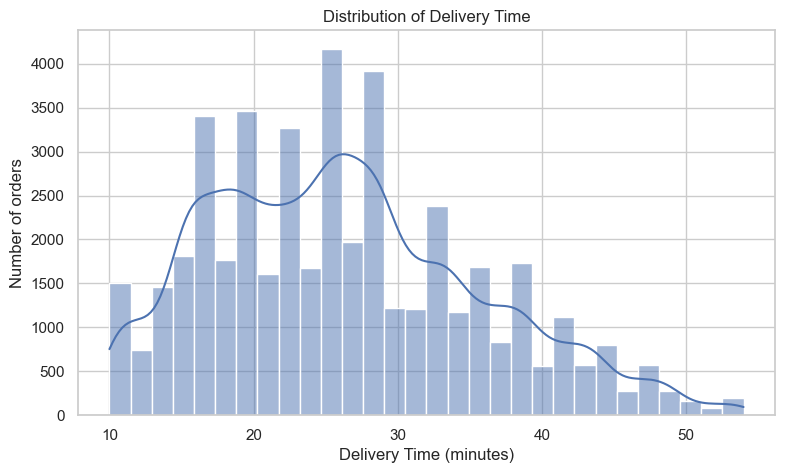

In [7]:
df_eda = df.copy()

df_eda["Time_taken(min)"] = pd.to_numeric(
    df_eda["Time_taken(min)"].astype("string").str.extract(r"(\d+(?:\.\d+)?)", expand=False),
    errors="coerce"
)

display(df_eda["Time_taken(min)"].describe())

plt.figure(figsize=(9, 5))
sns.histplot(df_eda["Time_taken(min)"], bins=30, kde=True)
plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Number of orders")
plt.show()

In [8]:
import numpy as np

# convert latitude and longitude from degrees to radians

restaurant_lat = np.radians(df["Restaurant_latitude"])
restaurant_lon = np.radians(df["Restaurant_longitude"])

delivery_lat = np.radians(df["Delivery_location_latitude"])
delivery_lon = np.radians(df["Delivery_location_longitude"])

# calculate differences

lat_difference = delivery_lat - restaurant_lat
lon_difference = delivery_lon - restaurant_lon

# haversine formula

a = (
    np.sin(lat_difference / 2) ** 2
    + np.cos(restaurant_lat)
    * np.cos(delivery_lat)
    * np.sin(lon_difference / 2) ** 2
)

c = 2 * np.arcsin(np.sqrt(a))

# earth radius in kilometers

earth_radius = 6371

# create distance column

df["Distance_km"] = earth_radius * c

# display the result

df[[
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude",
    "Distance_km"
]].head()

,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Distance_km
0,22.745049,75.892471,22.765049,75.912471,3.025149
1,12.913041,77.683237,13.043041,77.813237,20.183530
2,12.914264,77.678400,12.924264,77.688400,1.552758
3,11.003669,76.976494,11.053669,77.026494,7.790401
4,12.972793,80.249982,13.012793,80.289982,6.210138


## 5. Statement 3 — Analyse delivery person age and ratings

Convert these two columns to numeric values for analysis.

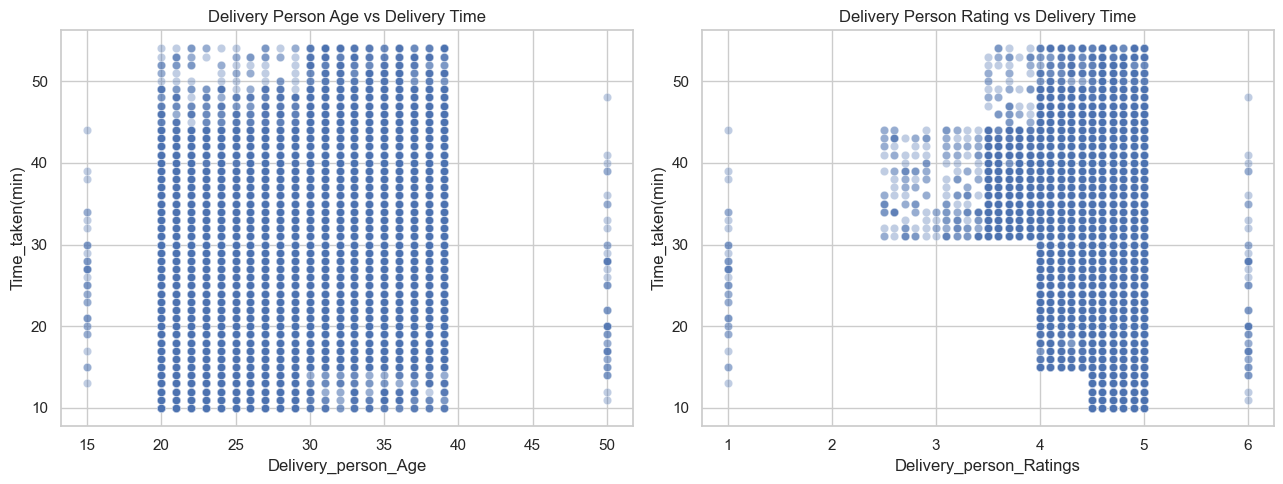

In [9]:
for col in ["Delivery_person_Age", "Delivery_person_Ratings"]:
    df_eda[col] = pd.to_numeric(df_eda[col], errors="coerce")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.scatterplot(data=df_eda, x="Delivery_person_Age", y="Time_taken(min)", alpha=0.35, ax=axes[0])
axes[0].set_title("Delivery Person Age vs Delivery Time")

sns.scatterplot(data=df_eda, x="Delivery_person_Ratings", y="Time_taken(min)", alpha=0.35, ax=axes[1])
axes[1].set_title("Delivery Person Rating vs Delivery Time")

plt.tight_layout()
plt.show()

## 6. Statement 4 — Analyse weather conditions

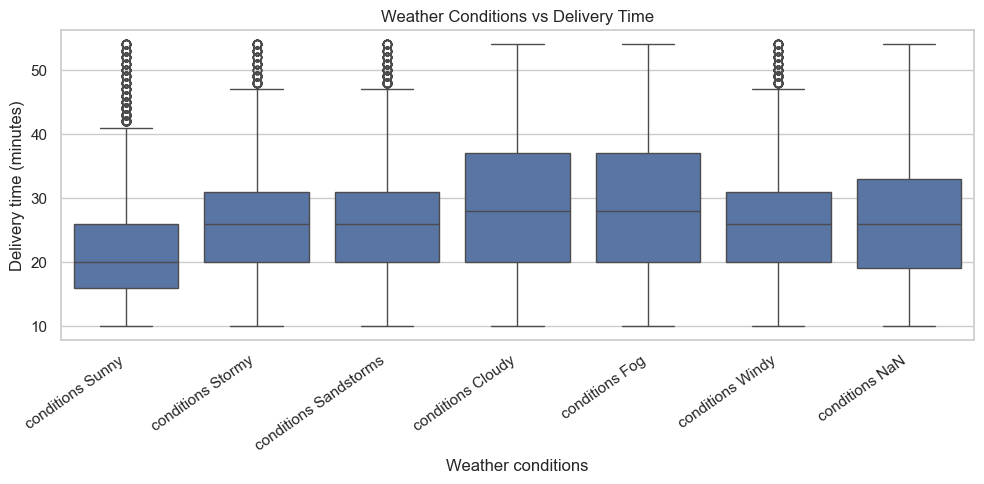

In [10]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_eda, x="Weatherconditions", y="Time_taken(min)")
plt.title("Weather Conditions vs Delivery Time")
plt.xlabel("Weather conditions")
plt.ylabel("Delivery time (minutes)")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 7. Statement 5 — Analyse road traffic density

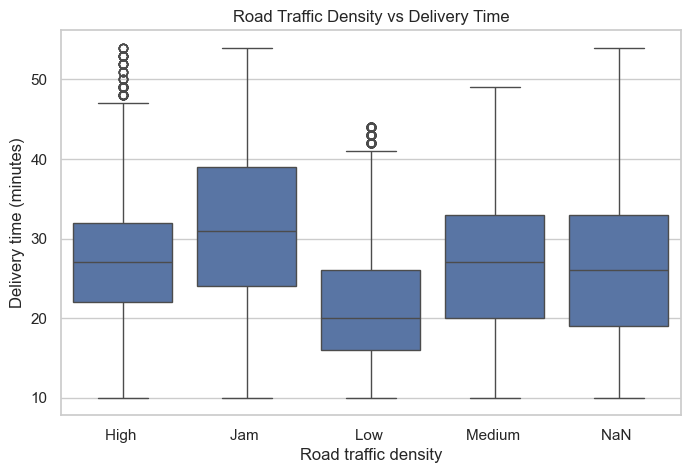

In [11]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_eda, x="Road_traffic_density", y="Time_taken(min)")
plt.title("Road Traffic Density vs Delivery Time")
plt.xlabel("Road traffic density")
plt.ylabel("Delivery time (minutes)")
plt.show()

## 8. Statement 6 — Analyse vehicle type and order type

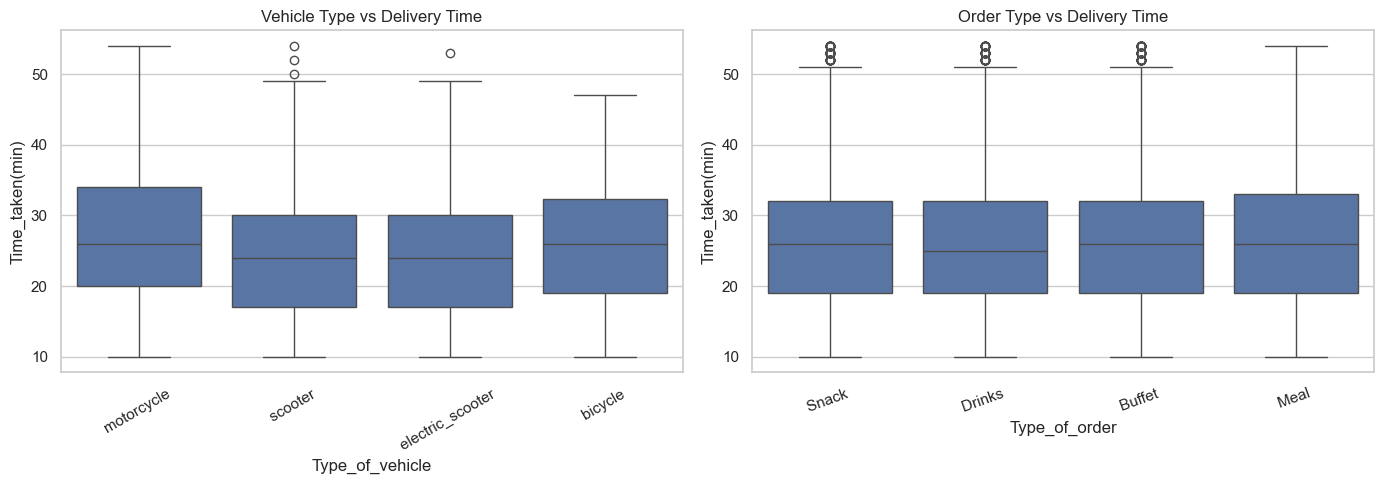

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df_eda, x="Type_of_vehicle", y="Time_taken(min)", ax=axes[0])
axes[0].set_title("Vehicle Type vs Delivery Time")
axes[0].tick_params(axis="x", rotation=30)

sns.boxplot(data=df_eda, x="Type_of_order", y="Time_taken(min)", ax=axes[1])
axes[1].set_title("Order Type vs Delivery Time")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

## 9. Statement 7 — Analyse multiple deliveries, festivals, and city categories

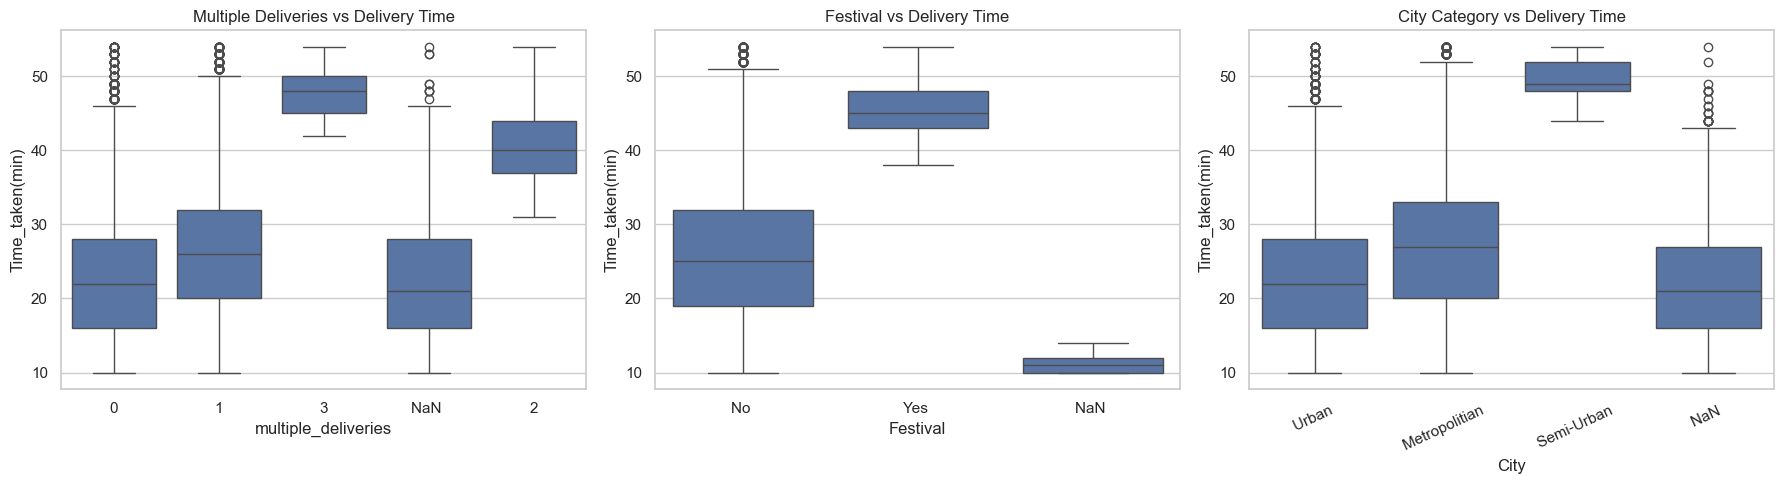

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=df_eda, x="multiple_deliveries", y="Time_taken(min)", ax=axes[0])
axes[0].set_title("Multiple Deliveries vs Delivery Time")

sns.boxplot(data=df_eda, x="Festival", y="Time_taken(min)", ax=axes[1])
axes[1].set_title("Festival vs Delivery Time")

sns.boxplot(data=df_eda, x="City", y="Time_taken(min)", ax=axes[2])
axes[2].set_title("City Category vs Delivery Time")
axes[2].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

## 10. Statement 8 — Check missing values, duplicates, unique values, and correlations

Missing values by column:


,missing_count
ID,0
Delivery_person_ID,0
Delivery_person_Age,1854
Delivery_person_Ratings,1908
Restaurant_latitude,0
Restaurant_longitude,0
Delivery_location_latitude,0
Delivery_location_longitude,0
Order_Date,0
Time_Orderd,0


Exact duplicate rows: 0
Unique values by column:


,unique_values
ID,45593
Delivery_person_ID,1320
Delivery_person_Age,22
Delivery_person_Ratings,28
Restaurant_latitude,657
Restaurant_longitude,518
Delivery_location_latitude,4373
Delivery_location_longitude,4373
Order_Date,44
Time_Orderd,177


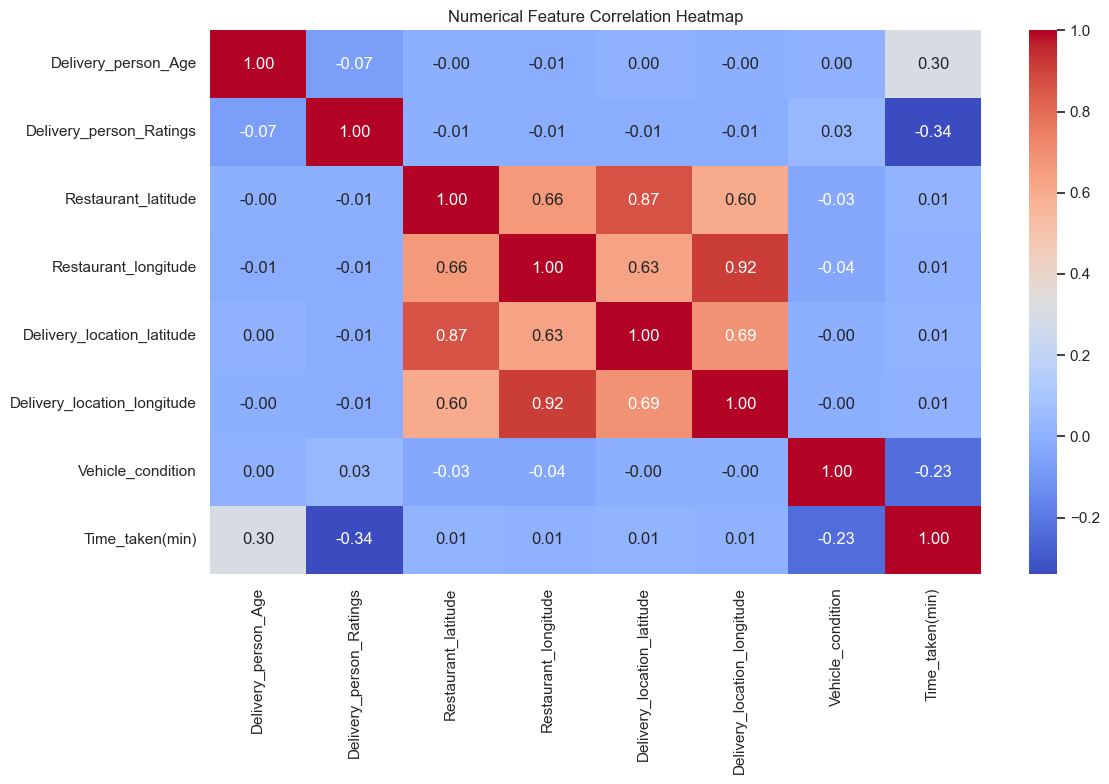

In [14]:
print("Missing values by column:")
display(df_eda.isna().sum().to_frame("missing_count"))

print("Exact duplicate rows:", df_eda.duplicated().sum())

print("Unique values by column:")
display(df_eda.nunique().to_frame("unique_values"))

numeric_eda = df_eda.select_dtypes(include=np.number)
plt.figure(figsize=(12, 8))
sns.heatmap(numeric_eda.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Numerical Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

# 11. Data cleaning

We keep the original `df` unchanged and create a separate `df_clean`.

Cleaning decisions:
- Strip spaces from column names and text values.
- Convert common placeholder strings to missing values.
- Remove exact duplicate rows.
- Convert numerical columns and target to numeric.
- Drop rows with a missing target because there is no correct delivery time to train on.
- Mark clearly invalid age, rating, and zero GPS coordinates as missing.
- Standardize weather labels.
- Do not automatically remove outliers; inspect them first.

In [15]:
df_clean = df.copy()

# Clean column names and text spacing
df_clean.columns = df_clean.columns.str.strip()

for col in df_clean.select_dtypes(include=["object", "string"]).columns:
    df_clean[col] = df_clean[col].astype("string").str.strip()

# Replace common placeholder values with missing values
placeholder_values = ["", "?", "Unknown", "unknown", "NA", "N/A", "null", "None"]
df_clean = df_clean.replace(placeholder_values, np.nan)

print("Shape before duplicate removal:", df_clean.shape)
print("Duplicate rows:", df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates().copy()
print("Shape after duplicate removal:", df_clean.shape)

Shape before duplicate removal: (45593, 21)
Duplicate rows: 0
Shape after duplicate removal: (45593, 21)


## 12. Convert numerical columns and clean the target

In [16]:
numeric_columns = [
    "Delivery_person_Age",
    "Delivery_person_Ratings",
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude",
    "Vehicle_condition",
    "multiple_deliveries"
]

for col in numeric_columns:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")

# Extract target minutes from values such as '(min) 24'
df_clean["Time_taken(min)"] = pd.to_numeric(
    df_clean["Time_taken(min)"].astype("string").str.extract(
        r"(\d+(?:\.\d+)?)", expand=False
    ),
    errors="coerce"
)

# Remove rows without a valid target value
before = len(df_clean)
df_clean = df_clean.dropna(subset=["Time_taken(min)"]).copy()
print("Rows removed because target was missing/invalid:", before - len(df_clean))

Rows removed because target was missing/invalid: 0


## 13. Handle clearly invalid values

These are validation rules for this dataset, not proof that every unusual record is wrong. Invalid values are marked missing and later imputed using training data only.

In [17]:
# Age: values outside this plausible working-age range are treated as invalid
df_clean.loc[
    ~df_clean["Delivery_person_Age"].between(18, 65),
    "Delivery_person_Age"
] = np.nan

# Ratings are expected to be on a 1 to 5 scale
df_clean.loc[
    ~df_clean["Delivery_person_Ratings"].between(1, 5),
    "Delivery_person_Ratings"
] = np.nan

# Coordinates equal to zero are not plausible for the listed Indian delivery cities
coordinate_columns = [
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude"
]
for col in coordinate_columns:
    df_clean.loc[df_clean[col] == 0, col] = np.nan

# Delivery time must be positive
df_clean.loc[df_clean["Time_taken(min)"] <= 0, "Time_taken(min)"] = np.nan
df_clean = df_clean.dropna(subset=["Time_taken(min)"]).copy()

print("Missing values after validity checks:")
display(df_clean.isna().sum().to_frame("missing_count"))

Missing values after validity checks:


,missing_count
ID,0
Delivery_person_ID,0
Delivery_person_Age,1892
Delivery_person_Ratings,1961
Restaurant_latitude,3640
Restaurant_longitude,3640
Delivery_location_latitude,0
Delivery_location_longitude,0
Order_Date,0
Time_Orderd,0


## 14. Standardize categorical values

In [18]:
categorical_to_clean = [
    "Weatherconditions",
    "Road_traffic_density",
    "Type_of_order",
    "Type_of_vehicle",
    "Festival",
    "City"
]

for col in categorical_to_clean:
    df_clean[col] = df_clean[col].astype("string").str.strip()

# Remove the repeated 'conditions' prefix from weather labels
df_clean["Weatherconditions"] = (
    df_clean["Weatherconditions"]
    .str.replace(r"(?i)^conditions\s*", "", regex=True)
    .str.title()
)

# Standardize category capitalization
for col in ["Road_traffic_density", "Type_of_order", "Type_of_vehicle", "Festival", "City"]:
    df_clean[col] = df_clean[col].str.title()

for col in categorical_to_clean:
    print("\n", col)
    print(df_clean[col].value_counts(dropna=False))


 Weatherconditions
Weatherconditions
Fog           7654
Stormy        7586
Cloudy        7536
Sandstorms    7495
Windy         7422
Sunny         7284
Nan            616
Name: count, dtype: Int64

 Road_traffic_density
Road_traffic_density
Low       15477
Jam       14143
Medium    10947
High       4425
Nan         601
Name: count, dtype: Int64

 Type_of_order
Type_of_order
Snack     11533
Meal      11458
Drinks    11322
Buffet    11280
Name: count, dtype: Int64

 Type_of_vehicle
Type_of_vehicle
Motorcycle          26435
Scooter             15276
Electric_Scooter     3814
Bicycle                68
Name: count, dtype: Int64

 Festival
Festival
No     44469
Yes      896
Nan      228
Name: count, dtype: Int64

 City
City
Metropolitian    34093
Urban            10136
Nan               1200
Semi-Urban         164
Name: count, dtype: Int64


## 15. Convert date and time fields and create time features

We extract numeric hour/minute information and pickup delay. The time difference is calculated modulo 24 hours to handle midnight crossings.

In [19]:
df_clean["Order_Date"] = pd.to_datetime(
    df_clean["Order_Date"], format="%d-%m-%Y", errors="coerce"
)

def time_to_minutes(series):
    parsed = pd.to_datetime(series, format="%H:%M:%S", errors="coerce")
    return parsed.dt.hour * 60 + parsed.dt.minute

df_clean["Order_Minutes"] = time_to_minutes(df_clean["Time_Orderd"])
df_clean["Pickup_Minutes"] = time_to_minutes(df_clean["Time_Order_picked"])

df_clean["Pickup_Delay_Minutes"] = (
    df_clean["Pickup_Minutes"] - df_clean["Order_Minutes"]
) % 1440

df_clean["Order_Hour"] = (df_clean["Order_Minutes"] // 60).astype("float")
df_clean["Order_Day"] = df_clean["Order_Date"].dt.day
df_clean["Order_Month"] = df_clean["Order_Date"].dt.month
df_clean["Order_Weekday"] = df_clean["Order_Date"].dt.dayofweek

display(df_clean[[
    "Order_Date", "Time_Orderd", "Time_Order_picked",
    "Order_Hour", "Pickup_Delay_Minutes", "Order_Weekday"
]].head())

,Order_Date,Time_Orderd,Time_Order_picked,Order_Hour,Pickup_Delay_Minutes,Order_Weekday
0,2022-03-19,11:30:00,11:45:00,11.0,15.0,5
1,2022-03-25,19:45:00,19:50:00,19.0,5.0,4
2,2022-03-19,08:30:00,08:45:00,8.0,15.0,5
3,2022-04-05,18:00:00,18:10:00,18.0,10.0,1
4,2022-03-26,13:30:00,13:45:00,13.0,15.0,5


## 16. Feature engineering — calculate delivery distance

The Haversine formula estimates the straight-line distance between restaurant and delivery coordinates in kilometres. It is not the actual road distance.

In [20]:
def haversine_km(lat1, lon1, lat2, lon2):
    earth_radius_km = 6371.0

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)
    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    )
    return 2 * earth_radius_km * np.arcsin(np.sqrt(a))

df_clean["Distance_km"] = haversine_km(
    df_clean["Restaurant_latitude"],
    df_clean["Restaurant_longitude"],
    df_clean["Delivery_location_latitude"],
    df_clean["Delivery_location_longitude"]
)

display(df_clean[["Distance_km", "Time_taken(min)"]].describe())

,Distance_km,Time_taken(min)
count,41953.000000,45593.0
mean,107.060101,26.294607
std,1146.118637,9.383806
min,1.465067,10.0
25%,4.658001,19.0
50%,9.220368,26.0
75%,13.760880,32.0
max,19692.674606,54.0


## 17. Inspect outliers

We use boxplots and the IQR rule to flag unusual target values. We do not automatically delete them because long delivery times may be genuine events.

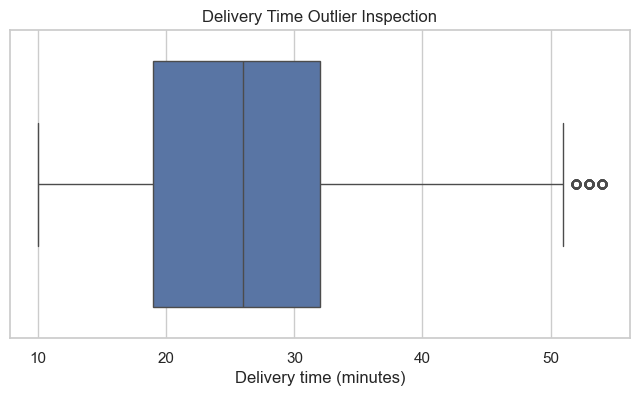

IQR lower bound: -0.5
IQR upper bound: 51.5
Potential target outliers: 270


In [21]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_clean["Time_taken(min)"])
plt.title("Delivery Time Outlier Inspection")
plt.xlabel("Delivery time (minutes)")
plt.show()

q1 = df_clean["Time_taken(min)"].quantile(0.25)
q3 = df_clean["Time_taken(min)"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_count = (
    (df_clean["Time_taken(min)"] < lower_bound)
    | (df_clean["Time_taken(min)"] > upper_bound)
).sum()

print("IQR lower bound:", lower_bound)
print("IQR upper bound:", upper_bound)
print("Potential target outliers:", outlier_count)

## 18. Prepare modelling data

We exclude:
- `Time_taken(min)` from X because it is the target.
- `ID` because it is only a record identifier.
- `Delivery_person_ID` to reduce the risk of the model memorizing individual delivery-person identifiers.
- Raw date/time text columns after extracting useful numeric features.

Missing values and encoding are handled inside a scikit-learn pipeline. This means imputers and scalers are fitted on training data only, reducing data leakage.

In [22]:
target = "Time_taken(min)"

columns_to_drop = [
    target,
    "ID",
    "Delivery_person_ID",
    "Order_Date",
    "Time_Orderd",
    "Time_Order_picked",
    "Order_Minutes",
    "Pickup_Minutes"
]

X = df_clean.drop(columns=columns_to_drop, errors="ignore")
y = df_clean[target].astype(float)

# Remove columns that are entirely empty
X = X.dropna(axis=1, how="all")

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Feature columns:")
print(X.columns.tolist())

display(X.head())

Feature shape: (45593, 20)
Target shape: (45593,)
Feature columns:
['Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Weatherconditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Distance_km', 'Pickup_Delay_Minutes', 'Order_Hour', 'Order_Day', 'Order_Month', 'Order_Weekday']


,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Distance_km,Pickup_Delay_Minutes,Order_Hour,Order_Day,Order_Month,Order_Weekday
0,37,4.9,22.745049,75.892471,22.765049,75.912471,Sunny,High,2,Snack,Motorcycle,0,No,Urban,3.025149,15.0,11.0,19,3,5
1,34,4.5,12.913041,77.683237,13.043041,77.813237,Stormy,Jam,2,Snack,Scooter,1,No,Metropolitian,20.183530,5.0,19.0,25,3,4
2,23,4.4,12.914264,77.678400,12.924264,77.688400,Sandstorms,Low,0,Drinks,Motorcycle,1,No,Urban,1.552758,15.0,8.0,19,3,5
3,38,4.7,11.003669,76.976494,11.053669,77.026494,Sunny,Medium,0,Buffet,Motorcycle,1,No,Metropolitian,7.790401,10.0,18.0,5,4,1
4,32,4.6,12.972793,80.249982,13.012793,80.289982,Cloudy,High,1,Snack,Scooter,1,No,Metropolitian,6.210138,15.0,13.0,26,3,5


## 19. Split data into training and testing sets

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 36474
Testing records: 9119


## 20. Preprocessing pipeline

Numerical features: median imputation and scaling.

Categorical features: most-frequent imputation and one-hot encoding.

Preprocessing is fitted separately within each model pipeline using only the training data.

In [24]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Vehicle_condition', 'multiple_deliveries', 'Distance_km', 'Pickup_Delay_Minutes', 'Order_Hour', 'Order_Day', 'Order_Month', 'Order_Weekday']
Categorical features: ['Weatherconditions', 'Road_traffic_density', 'Type_of_order', 'Type_of_vehicle', 'Festival', 'City']


## 21. Train regression models

We compare Linear Regression, Decision Tree, Random Forest, and Gradient Boosting.

In [26]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=12, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=RANDOM_STATE
    )
}

trained_models = {}

for model_name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[model_name] = pipeline

    print(model_name, "training completed")

Linear Regression training completed
Decision Tree training completed
Random Forest training completed
Gradient Boosting training completed


## 22. Evaluate models

Metrics:
- MAE: average absolute prediction error in minutes; lower is better.
- RMSE: gives more weight to larger errors; lower is better.
- R²: proportion of target variation explained by the model; closer to 1 is generally better.

In [27]:
results = []
predictions = {}

for model_name, pipeline in trained_models.items():
    y_pred = pipeline.predict(X_test)
    predictions[model_name] = y_pred

    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": model_name,
        "MAE (minutes)": mae,
        "RMSE (minutes)": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results).sort_values("MAE (minutes)")
display(results_df)

,Model,MAE (minutes),RMSE (minutes),R2 Score
2,Random Forest,3.230158,4.065082,0.811528
1,Decision Tree,3.364921,4.291752,0.789923
3,Gradient Boosting,3.702758,4.650264,0.753360
0,Linear Regression,4.886610,6.200175,0.561553


## 23. Compare actual and predicted delivery times for the best model

Best model based on lowest MAE: Random Forest


,Actual Delivery Time,Predicted Delivery Time
0,44.0,42.421188
1,41.0,44.153339
2,39.0,36.192595
3,38.0,41.608536
4,38.0,42.657173
5,22.0,22.412143
6,14.0,15.770750
7,17.0,22.327966
8,22.0,21.646857
9,29.0,26.365107


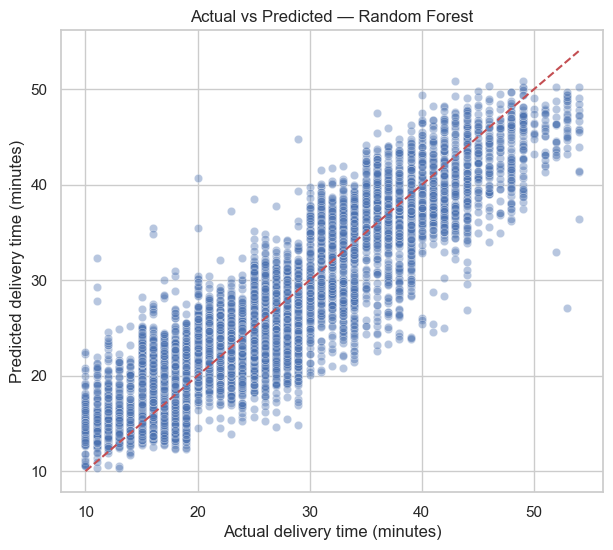

In [28]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]
best_predictions = predictions[best_model_name]

print("Best model based on lowest MAE:", best_model_name)

comparison = pd.DataFrame({
    "Actual Delivery Time": y_test.reset_index(drop=True),
    "Predicted Delivery Time": best_predictions
})

display(comparison.head(15))

plt.figure(figsize=(7, 6))
sns.scatterplot(
    x=y_test,
    y=best_predictions,
    alpha=0.4
)
min_value = min(y_test.min(), best_predictions.min())
max_value = max(y_test.max(), best_predictions.max())
plt.plot([min_value, max_value], [min_value, max_value], "r--")
plt.xlabel("Actual delivery time (minutes)")
plt.ylabel("Predicted delivery time (minutes)")
plt.title(f"Actual vs Predicted — {best_model_name}")
plt.show()

## 24. Inspect feature importance (tree-based best model only)

Feature importance is available for Random Forest, Decision Tree, and Gradient Boosting. If Linear Regression is selected as the best model, this cell will explain that tree-based importance is not available for that selected model.

,Feature,Importance
1,num__Delivery_person_Ratings,0.202601
7,num__multiple_deliveries,0.118843
23,cat__Road_traffic_density_Low,0.109898
8,num__Distance_km,0.100658
0,num__Delivery_person_Age,0.087303
6,num__Vehicle_condition,0.067639
19,cat__Weatherconditions_Sunny,0.066471
15,cat__Weatherconditions_Fog,0.036877
14,cat__Weatherconditions_Cloudy,0.036160
5,num__Delivery_location_longitude,0.019184


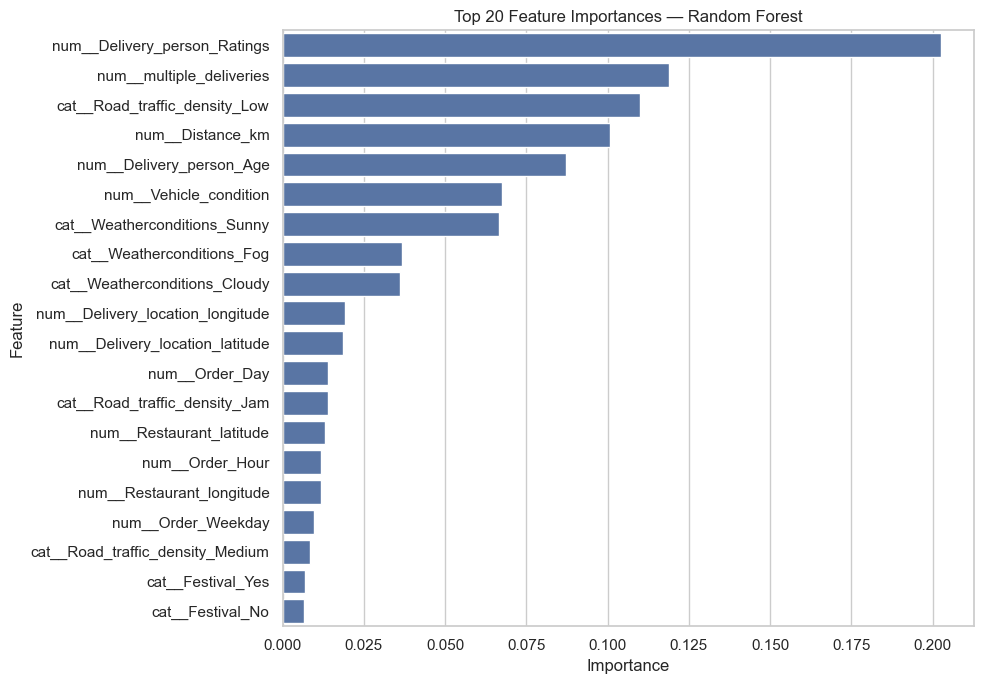

In [29]:
best_estimator = best_model.named_steps["model"]

if hasattr(best_estimator, "feature_importances_"):
    feature_names = best_model.named_steps["preprocessor"].get_feature_names_out()
    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": best_estimator.feature_importances_
    }).sort_values("Importance", ascending=False).head(20)

    display(importance_df)

    plt.figure(figsize=(10, 7))
    sns.barplot(data=importance_df, x="Importance", y="Feature")
    plt.title(f"Top 20 Feature Importances — {best_model_name}")
    plt.tight_layout()
    plt.show()
else:
    print(
        "The selected best model is not a tree-based model. "
        "Feature importance is not available through feature_importances_."
    )

## 25. Save the best complete model pipeline

The saved pipeline includes preprocessing and the trained model. Save the exact feature-column order too.

In [30]:
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

model_path = output_dir / "best_delivery_time_model.joblib"
columns_path = output_dir / "model_feature_columns.joblib"

joblib.dump(best_model, model_path)
joblib.dump(X.columns.tolist(), columns_path)

print("Saved model:", model_path)
print("Saved feature columns:", columns_path)

Saved model: outputs\best_delivery_time_model.joblib
Saved feature columns: outputs\model_feature_columns.joblib


## 26. Make a prediction for one test record

This uses one row from the test set, so it demonstrates how to call the saved model pipeline. The output is a predicted delivery time in minutes.

In [31]:
sample_input = X_test.iloc[[0]].copy()
actual_time = y_test.iloc[0]

predicted_time = best_model.predict(sample_input)[0]

print("Actual delivery time:", round(float(actual_time), 2), "minutes")
print("Predicted delivery time:", round(float(predicted_time), 2), "minutes")

Actual delivery time: 44.0 minutes
Predicted delivery time: 42.42 minutes


## 27. Save the cleaned dataset and final summary

In [32]:
cleaned_path = output_dir / "cleaned_delivery_dataset.csv"
df_clean.to_csv(cleaned_path, index=False)

print("Cleaned dataset saved to:", cleaned_path)
print("Final cleaned dataset shape:", df_clean.shape)
print("Target column:", target)
print("Selected model:", best_model_name)
print("Test MAE:", round(float(results_df.iloc[0]["MAE (minutes)"]), 3), "minutes")
print("Test RMSE:", round(float(results_df.iloc[0]["RMSE (minutes)"]), 3), "minutes")
print("Test R2:", round(float(results_df.iloc[0]["R2 Score"]), 3))

Cleaned dataset saved to: outputs\cleaned_delivery_dataset.csv
Final cleaned dataset shape: (45593, 28)
Target column: Time_taken(min)
Selected model: Random Forest
Test MAE: 3.23 minutes
Test RMSE: 4.065 minutes
Test R2: 0.812


### Problem Statement 5 – Flag Late Orders (Classification)

In [33]:
from sklearn.linear_model import LogisticRegression

from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve
)

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [34]:
SLA_MINUTES = 30

df_ps5 = df_clean.copy()

df_ps5["Late_Order"] = (
    df_ps5["Time_taken(min)"] > SLA_MINUTES
).astype(int)

print("Late order distribution:")
print(df_ps5["Late_Order"].value_counts())

print("\nLate order percentage:")
print(df_ps5["Late_Order"].value_counts(normalize=True) * 100)

Late order distribution:
Late_Order
0    31987
1    13606
Name: count, dtype: int64

Late order percentage:
Late_Order
0    70.1577
1    29.8423
Name: proportion, dtype: float64


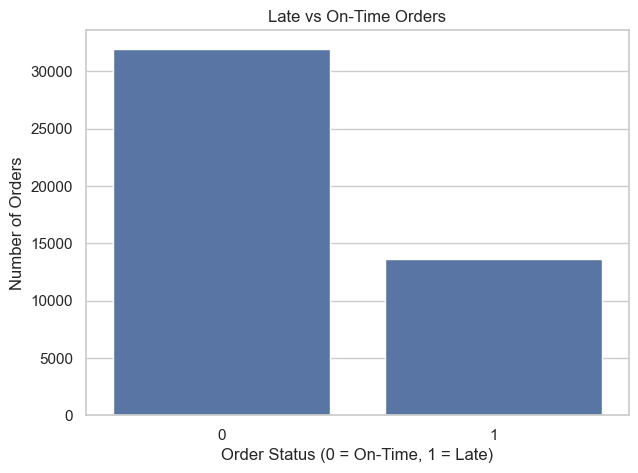

In [35]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df_ps5,
    x="Late_Order"
)

plt.title("Late vs On-Time Orders")
plt.xlabel("Order Status (0 = On-Time, 1 = Late)")
plt.ylabel("Number of Orders")

plt.show()

In [37]:
features = [
    "Distance_km",
    "Order_Hour",
    "Order_Weekday",
    "Order_Month",
    "Restaurant_latitude",
    "Restaurant_longitude",
    "Delivery_location_latitude",
    "Delivery_location_longitude",
    "Weatherconditions",
    "Road_traffic_density",
    "Type_of_order",
    "City",
    "Festival"
]

X_late = df_ps5[features].copy()

y_late = df_ps5["Late_Order"].copy()

print("Feature shape:", X_late.shape)

print("Target shape:", y_late.shape)

display(X_late.head())

Feature shape: (45593, 13)
Target shape: (45593,)


,Distance_km,Order_Hour,Order_Weekday,Order_Month,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Weatherconditions,Road_traffic_density,Type_of_order,City,Festival
0,3.025149,11.0,5,3,22.745049,75.892471,22.765049,75.912471,Sunny,High,Snack,Urban,No
1,20.183530,19.0,4,3,12.913041,77.683237,13.043041,77.813237,Stormy,Jam,Snack,Metropolitian,No
2,1.552758,8.0,5,3,12.914264,77.678400,12.924264,77.688400,Sandstorms,Low,Drinks,Urban,No
3,7.790401,18.0,1,4,11.003669,76.976494,11.053669,77.026494,Sunny,Medium,Buffet,Metropolitian,No
4,6.210138,13.0,5,3,12.972793,80.249982,13.012793,80.289982,Cloudy,High,Snack,Metropolitian,No


In [38]:
X_train_full, X_test_late, y_train_full, y_test_late = train_test_split(
    X_late,
    y_late,
    test_size=0.20,
    random_state=42,
    stratify=y_late
)

X_train_late, X_val_late, y_train_late, y_val_late = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.25,
    random_state=42,
    stratify=y_train_full
)

print("Training records:", len(X_train_late))
print("Validation records:", len(X_val_late))
print("Testing records:", len(X_test_late))

Training records: 27355
Validation records: 9119
Testing records: 9119


In [39]:
numeric_features_cls = X_train_late.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features_cls = X_train_late.select_dtypes(
    exclude=np.number
).columns.tolist()

numeric_transformer_cls = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer_cls = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor_cls = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer_cls, numeric_features_cls),
        ("cat", categorical_transformer_cls, categorical_features_cls)
    ]
)

print("Preprocessing completed.")

Preprocessing completed.


In [40]:
late_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    )
}

In [41]:
late_pipelines = {}

for model_name, model in late_models.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor_cls),
        ("model", model)
    ])

    pipeline.fit(X_train_late, y_train_late)

    late_pipelines[model_name] = pipeline

    print(model_name, "training completed")

Logistic Regression training completed
Random Forest training completed
Gradient Boosting training completed


In [42]:
late_results = []

validation_probabilities = {}

for model_name, pipeline in late_pipelines.items():

    y_probability = pipeline.predict_proba(X_val_late)[:, 1]

    y_prediction = (y_probability >= 0.50).astype(int)

    validation_probabilities[model_name] = y_probability

    late_results.append({
        "Model": model_name,

        "Accuracy": accuracy_score(
            y_val_late, y_prediction
        ),

        "Precision": precision_score(
            y_val_late, y_prediction, zero_division=0
        ),

        "Recall": recall_score(
            y_val_late, y_prediction, zero_division=0
        ),

        "F1 Score": f1_score(
            y_val_late, y_prediction, zero_division=0
        ),

        "PR-AUC": average_precision_score(
            y_val_late, y_probability
        ),

        "ROC-AUC": roc_auc_score(
            y_val_late, y_probability
        )
    })

classification_results = pd.DataFrame(late_results)

classification_results = classification_results.sort_values(
    by="PR-AUC",
    ascending=False
)

display(classification_results)

,Model,Accuracy,Precision,Recall,F1 Score,PR-AUC,ROC-AUC
2,Gradient Boosting,0.798004,0.745394,0.490628,0.591755,0.736141,0.851860
1,Random Forest,0.788025,0.698389,0.509739,0.589335,0.730254,0.840195
0,Logistic Regression,0.699967,0.498243,0.781698,0.608584,0.663606,0.807475


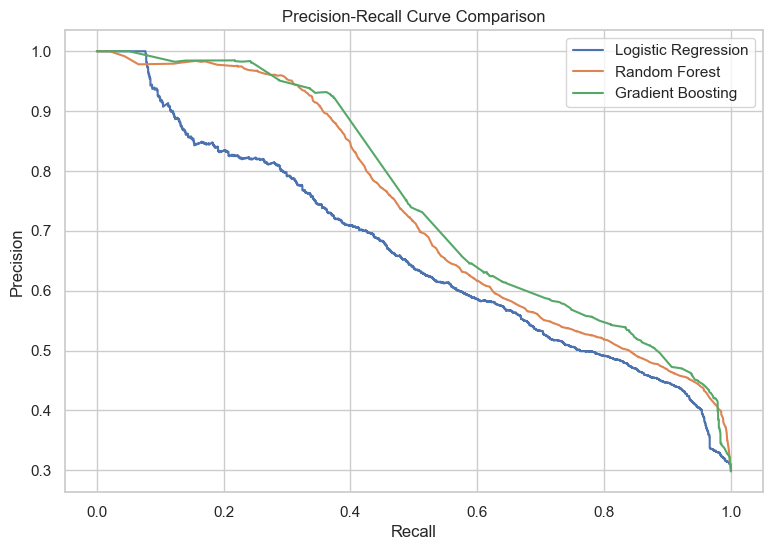

In [43]:
plt.figure(figsize=(9, 6))

for model_name, pipeline in late_pipelines.items():

    y_probability = validation_probabilities[model_name]

    precision, recall, thresholds = precision_recall_curve(
        y_val_late,
        y_probability
    )

    plt.plot(
        recall,
        precision,
        label=model_name
    )

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title("Precision-Recall Curve Comparison")

plt.legend()

plt.grid(True)

plt.show()

In [44]:
best_late_model_name = classification_results.iloc[0]["Model"]

best_late_model = late_pipelines[best_late_model_name]

print("Selected classifier:", best_late_model_name)

print(
    "Validation PR-AUC:",
    classification_results.iloc[0]["PR-AUC"]
)

Selected classifier: Gradient Boosting
Validation PR-AUC: 0.7361409544778327


In [45]:
COST_MISSED_LATE = 500

COST_UNNECESSARY_INTERVENTION = 50

val_probability = validation_probabilities[
    best_late_model_name
]

threshold_results = []

for threshold in np.arange(0.05, 1.00, 0.05):

    y_pred = (
        val_probability >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_late,
        y_pred,
        labels=[0, 1]
    ).ravel()

    total_cost = (
        fn * COST_MISSED_LATE
        + fp * COST_UNNECESSARY_INTERVENTION
    )

    threshold_results.append({
        "Threshold": threshold,
        "False Positives": fp,
        "False Negatives": fn,
        "Total Cost": total_cost
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df)

best_threshold = threshold_df.loc[
    threshold_df["Total Cost"].idxmin(),
    "Threshold"
]

print("Best cost-based threshold:", best_threshold)

,Threshold,False Positives,False Negatives,Total Cost
0,0.05,4707,46,258350
1,0.10,3724,60,216200
2,0.15,3350,106,220500
3,0.20,2830,210,246500
4,0.25,2128,407,309900
5,0.30,1851,516,350550
6,0.35,1528,689,420900
7,0.40,977,1049,573350
8,0.45,510,1329,690000
9,0.50,456,1386,715800


Best cost-based threshold: 0.1


In [46]:
cost_scenarios = [
    (500, 50),
    (1000, 50),
    (500, 200)
]

scenario_results = []

for missed_cost, intervention_cost in cost_scenarios:

    costs = []

    for threshold in np.arange(0.05, 1.00, 0.05):

        y_pred = (
            val_probability >= threshold
        ).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val_late,
            y_pred,
            labels=[0, 1]
        ).ravel()

        cost = (
            fn * missed_cost
            + fp * intervention_cost
        )

        costs.append((threshold, cost))

    best_option = min(costs, key=lambda x: x[1])

    scenario_results.append({
        "Missed Late Cost": missed_cost,
        "Unnecessary Intervention Cost": intervention_cost,
        "Best Threshold": best_option[0],
        "Minimum Cost": best_option[1]
    })

display(pd.DataFrame(scenario_results))

,Missed Late Cost,Unnecessary Intervention Cost,Best Threshold,Minimum Cost
0,500,50,0.1,216200
1,1000,50,0.1,246200
2,500,200,0.3,628200


In [47]:
final_classifier = Pipeline(steps=[
    ("preprocessor", preprocessor_cls),
    ("model", late_models[best_late_model_name])
])

final_classifier.fit(X_train_full, y_train_full)

test_probability = final_classifier.predict_proba(
    X_test_late
)[:, 1]

test_prediction = (
    test_probability >= best_threshold
).astype(int)

print("Accuracy:", accuracy_score(
    y_test_late, test_prediction
))

print("Precision:", precision_score(
    y_test_late, test_prediction, zero_division=0
))

print("Recall:", recall_score(
    y_test_late, test_prediction, zero_division=0
))

print("F1 Score:", f1_score(
    y_test_late, test_prediction, zero_division=0
))

print("PR-AUC:", average_precision_score(
    y_test_late, test_probability
))

print("\nClassification Report:")

print(classification_report(
    y_test_late,
    test_prediction,
    zero_division=0
))

print("Confusion Matrix:")

print(confusion_matrix(
    y_test_late,
    test_prediction
))

Accuracy: 0.587345103629784
Precision: 0.4186191815057794
Recall: 0.9849320102903344
F1 Score: 0.5875260331031459
PR-AUC: 0.7415534501986781

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.42      0.59      6398
           1       0.42      0.98      0.59      2721

    accuracy                           0.59      9119
   macro avg       0.70      0.70      0.59      9119
weighted avg       0.82      0.59      0.59      9119

Confusion Matrix:
[[2676 3722]
 [  41 2680]]


In [42]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test_late, test_prediction)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[2676 3722]
 [  41 2680]]


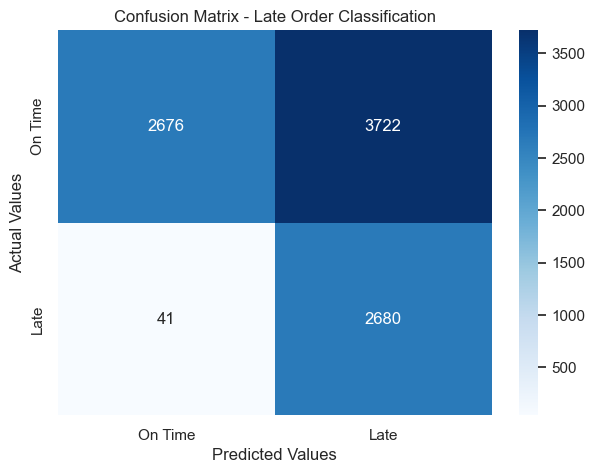

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test_late, test_prediction)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["On Time", "Late"],
    yticklabels=["On Time", "Late"]
)

plt.title("Confusion Matrix - Late Order Classification")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

### Problem Statement 6 – Find Ideal Dark-Store Zones (K-Means)

In [44]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [45]:
store_data = df_ps5.copy()

store_data = store_data.dropna(
    subset=[
        "Restaurant_latitude",
        "Restaurant_longitude"
    ]
)

store_data = store_data[
    store_data["Restaurant_latitude"].between(-90, 90)
    & store_data["Restaurant_longitude"].between(-180, 180)
]

store_data = store_data[
    (store_data["Restaurant_latitude"] != 0)
    & (store_data["Restaurant_longitude"] != 0)
]

store_data["Store_Lat"] = store_data[
    "Restaurant_latitude"
].round(4)

store_data["Store_Lon"] = store_data[
    "Restaurant_longitude"
].round(4)

store_points = store_data.groupby(
    ["Store_Lat", "Store_Lon"]
).agg(
    Order_Count=("ID", "count"),
    Average_Delivery_Time=("Time_taken(min)", "mean"),
    Late_Rate=("Late_Order", "mean")
).reset_index()

print("Number of store locations:", len(store_points))

display(store_points.head())

Number of store locations: 703


,Store_Lat,Store_Lon,Order_Count,Average_Delivery_Time,Late_Rate
0,-30.9056,-75.8328,1,16.0,0.000000
1,-30.9029,75.8268,2,22.5,0.000000
2,-30.8996,75.8093,3,22.333333,0.000000
3,-30.8958,75.8131,3,21.333333,0.333333
4,-30.8934,-75.8212,1,15.0,0.000000


In [46]:
mean_latitude = store_points["Store_Lat"].mean()

store_points["Adjusted_Lon"] = (
    store_points["Store_Lon"]
    * np.cos(np.radians(mean_latitude))
)

cluster_features = store_points[
    ["Store_Lat", "Adjusted_Lon"]
].values

print("Clustering features prepared.")

Clustering features prepared.


In [47]:
silhouette_results = []

maximum_k = min(8, len(store_points) - 1)

for k in range(2, maximum_k + 1):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(
        cluster_features,
        sample_weight=store_points["Order_Count"]
    )

    score = silhouette_score(
        cluster_features,
        labels,
        sample_size=min(3000, len(store_points)),
        random_state=42
    )

    silhouette_results.append({
        "K": k,
        "Silhouette Score": score
    })

silhouette_df = pd.DataFrame(silhouette_results)

display(silhouette_df)

,K,Silhouette Score
0,2,0.870775
1,3,0.513089
2,4,0.442556
3,5,0.635765
4,6,0.667778
5,7,0.658490
6,8,0.665296


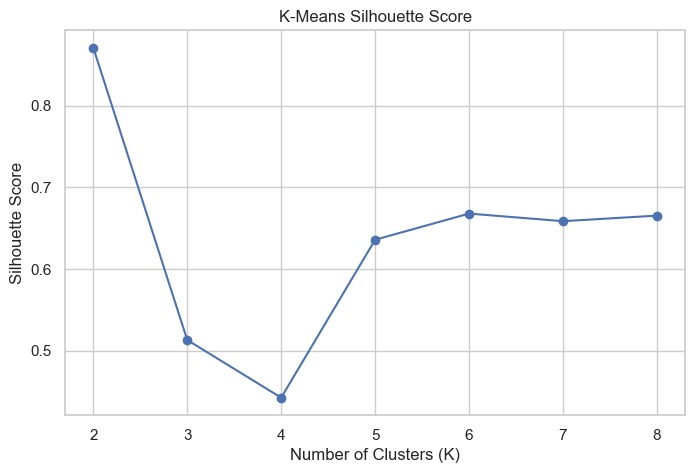

In [48]:
plt.figure(figsize=(8, 5))

plt.plot(
    silhouette_df["K"],
    silhouette_df["Silhouette Score"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")

plt.title("K-Means Silhouette Score")

plt.xticks(silhouette_df["K"])

plt.grid(True)

plt.show()

In [49]:
best_k = int(
    silhouette_df.loc[
        silhouette_df["Silhouette Score"].idxmax(),
        "K"
    ]
)

print("Best number of clusters:", best_k)

best_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

store_points["Zone_Cluster"] = best_kmeans.fit_predict(
    cluster_features,
    sample_weight=store_points["Order_Count"]
)

print("Clustering completed.")

Best number of clusters: 2
Clustering completed.


In [50]:
zone_summary = store_points.groupby(
    "Zone_Cluster"
).agg(
    Store_Locations=("Order_Count", "size"),
    Order_Demand=("Order_Count", "sum")
).reset_index()

weighted_zone_data = store_points.assign(
    Weighted_Delivery_Time=(
        store_points["Average_Delivery_Time"]
        * store_points["Order_Count"]
    ),
    Weighted_Late_Rate=(
        store_points["Late_Rate"]
        * store_points["Order_Count"]
    )
)

zone_metrics = weighted_zone_data.groupby(
    "Zone_Cluster"
).agg(
    Total_Weighted_Time=("Weighted_Delivery_Time", "sum"),
    Total_Weighted_Late=("Weighted_Late_Rate", "sum"),
    Total_Orders=("Order_Count", "sum")
).reset_index()

zone_summary = zone_summary.merge(
    zone_metrics,
    on="Zone_Cluster"
)

zone_summary["Average_Delivery_Time"] = (
    zone_summary["Total_Weighted_Time"]
    / zone_summary["Total_Orders"]
)

zone_summary["Late_Rate"] = (
    zone_summary["Total_Weighted_Late"]
    / zone_summary["Total_Orders"]
)

zone_summary["Late_Rate_Percentage"] = (
    zone_summary["Late_Rate"] * 100
)

zone_summary = zone_summary.drop(
    columns=[
        "Total_Weighted_Time",
        "Total_Weighted_Late",
        "Total_Orders",
        "Late_Rate"
    ]
)

display(zone_summary)

,Zone_Cluster,Store_Locations,Order_Demand,Average_Delivery_Time,Late_Rate_Percentage
0,0,574,41791,26.313489,29.960996
1,1,129,162,25.808642,23.456790


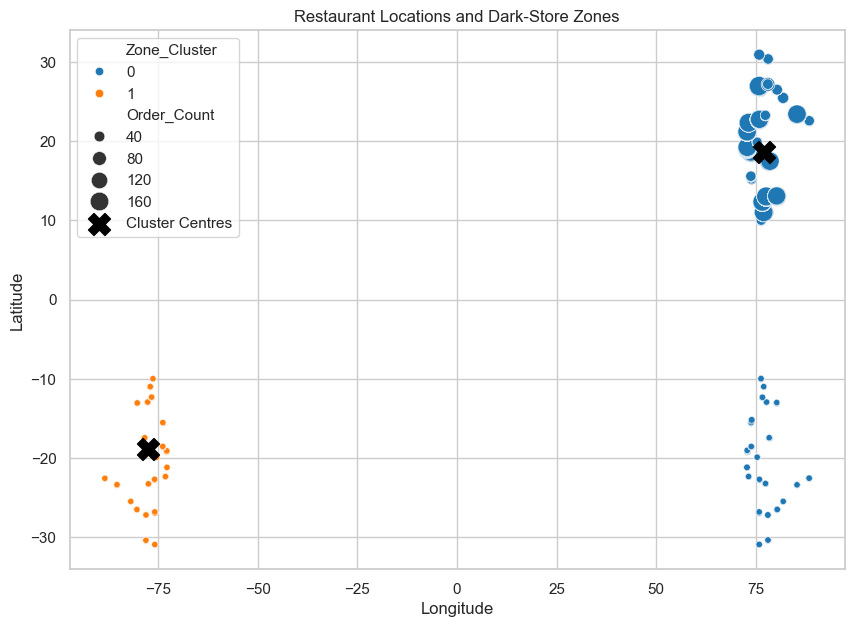

In [51]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=store_points,
    x="Store_Lon",
    y="Store_Lat",
    hue="Zone_Cluster",
    size="Order_Count",
    palette="tab10",
    sizes=(20, 200)
)

centres = best_kmeans.cluster_centers_

centre_lat = centres[:, 0]

centre_lon = (
    centres[:, 1]
    / np.cos(np.radians(mean_latitude))
)

plt.scatter(
    centre_lon,
    centre_lat,
    marker="X",
    s=250,
    color="black",
    label="Cluster Centres"
)

plt.title("Restaurant Locations and Dark-Store Zones")

plt.xlabel("Longitude")

plt.ylabel("Latitude")

plt.legend()

plt.show()

### Problem Statement 7 – Segment Rider Performance

In [52]:
rider_profile = df_ps5.groupby(
    "Delivery_person_ID"
).agg(
    Average_Age=("Delivery_person_Age", "mean"),

    Average_Rating=("Delivery_person_Ratings", "mean"),

    Average_Delivery_Time=("Time_taken(min)", "mean"),

    Late_Rate=("Late_Order", "mean")

).reset_index()

display(rider_profile.head())

,Delivery_person_ID,Average_Age,Average_Rating,Average_Delivery_Time,Late_Rate
0,AGRRES010DEL01,31.0,4.761538,24.5,0.142857
1,AGRRES010DEL02,29.0,4.671429,28.8,0.400000
2,AGRRES010DEL03,29.538462,4.6,27.615385,0.307692
3,AGRRES01DEL01,30.777778,4.522222,26.833333,0.333333
4,AGRRES01DEL02,30.571429,4.7,24.428571,0.214286


In [53]:
rider_daily = df_ps5.groupby(
    ["Delivery_person_ID", "Order_Date"]
).size().reset_index(name="Daily_Deliveries")

daily_average = rider_daily.groupby(
    "Delivery_person_ID"
)["Daily_Deliveries"].mean().reset_index()

daily_average = daily_average.rename(
    columns={
        "Daily_Deliveries": "Average_Daily_Deliveries"
    }
)

rider_profile = rider_profile.merge(
    daily_average,
    on="Delivery_person_ID",
    how="left"
)

display(rider_profile.head())

,Delivery_person_ID,Average_Age,Average_Rating,Average_Delivery_Time,Late_Rate,Average_Daily_Deliveries
0,AGRRES010DEL01,31.0,4.761538,24.5,0.142857,1.750000
1,AGRRES010DEL02,29.0,4.671429,28.8,0.400000,1.875000
2,AGRRES010DEL03,29.538462,4.6,27.615385,0.307692,1.857143
3,AGRRES01DEL01,30.777778,4.522222,26.833333,0.333333,1.714286
4,AGRRES01DEL02,30.571429,4.7,24.428571,0.214286,2.000000


In [54]:
rider_features = [
    "Average_Age",
    "Average_Rating",
    "Average_Delivery_Time",
    "Late_Rate",
    "Average_Daily_Deliveries"
]

rider_X = rider_profile[rider_features].copy()

rider_X = rider_X.fillna(
    rider_X.median()
)

rider_scaler = StandardScaler()

rider_X_scaled = rider_scaler.fit_transform(
    rider_X
)

print("Rider features prepared.")

Rider features prepared.


In [55]:
rider_silhouette_results = []

for k in range(2, min(7, len(rider_profile))):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(
        rider_X_scaled
    )

    score = silhouette_score(
        rider_X_scaled,
        labels
    )

    rider_silhouette_results.append({
        "K": k,
        "Silhouette Score": score
    })

rider_silhouette_df = pd.DataFrame(
    rider_silhouette_results
)

display(rider_silhouette_df)

,K,Silhouette Score
0,2,0.226078
1,3,0.184740
2,4,0.196421
3,5,0.162702
4,6,0.170331


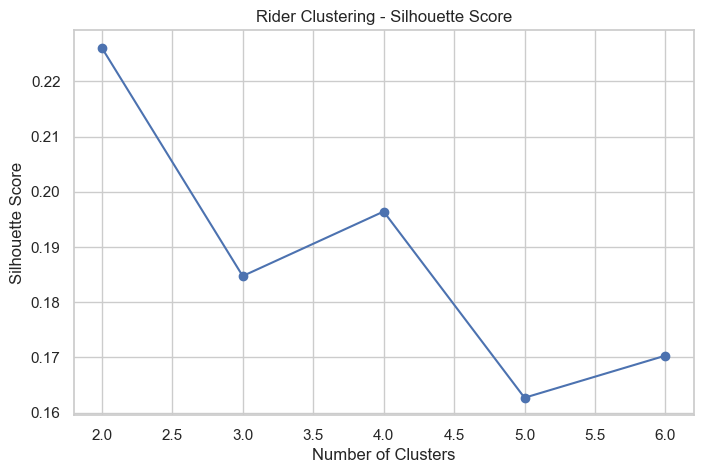

In [56]:
plt.figure(figsize=(8, 5))

plt.plot(
    rider_silhouette_df["K"],
    rider_silhouette_df["Silhouette Score"],
    marker="o"
)

plt.xlabel("Number of Clusters")

plt.ylabel("Silhouette Score")

plt.title("Rider Clustering - Silhouette Score")

plt.grid(True)

plt.show()

In [57]:
best_rider_k = int(
    rider_silhouette_df.loc[
        rider_silhouette_df["Silhouette Score"].idxmax(),
        "K"
    ]
)

print("Best rider clusters:", best_rider_k)

rider_kmeans = KMeans(
    n_clusters=best_rider_k,
    random_state=42,
    n_init=10
)

rider_profile["Rider_Cluster"] = (
    rider_kmeans.fit_predict(rider_X_scaled)
)

display(rider_profile.head())

Best rider clusters: 2


,Delivery_person_ID,Average_Age,Average_Rating,Average_Delivery_Time,Late_Rate,Average_Daily_Deliveries,Rider_Cluster
0,AGRRES010DEL01,31.0,4.761538,24.5,0.142857,1.750000,1
1,AGRRES010DEL02,29.0,4.671429,28.8,0.400000,1.875000,0
2,AGRRES010DEL03,29.538462,4.6,27.615385,0.307692,1.857143,0
3,AGRRES01DEL01,30.777778,4.522222,26.833333,0.333333,1.714286,0
4,AGRRES01DEL02,30.571429,4.7,24.428571,0.214286,2.000000,1


In [58]:
median_late_rate = rider_profile["Late_Rate"].median()

median_delivery_time = rider_profile[
    "Average_Delivery_Time"
].median()

median_rating = rider_profile[
    "Average_Rating"
].median()


def assign_rider_segment(row):

    if (
        row["Late_Rate"] <= median_late_rate
        and row["Average_Delivery_Time"] <= median_delivery_time
    ):
        return "Fast and Reliable"

    elif (
        row["Late_Rate"] > median_late_rate
        and row["Average_Delivery_Time"] > median_delivery_time
    ):
        return "Needs Support"

    elif row["Average_Rating"] >= median_rating:
        return "Good Rated / Mixed Speed"

    else:
        return "Mixed Performance"


rider_profile["Rider_Segment"] = rider_profile.apply(
    assign_rider_segment,
    axis=1
)

display(
    rider_profile[
        [
            "Delivery_person_ID",
            "Rider_Cluster",
            "Rider_Segment"
        ]
    ].head(15)
)

,Delivery_person_ID,Rider_Cluster,Rider_Segment
0,AGRRES010DEL01,1,Fast and Reliable
1,AGRRES010DEL02,0,Needs Support
2,AGRRES010DEL03,0,Needs Support
3,AGRRES01DEL01,0,Needs Support
4,AGRRES01DEL02,1,Fast and Reliable
5,AGRRES01DEL03,1,Fast and Reliable
6,AGRRES02DEL01,0,Needs Support
7,AGRRES02DEL02,1,Mixed Performance
8,AGRRES02DEL03,1,Fast and Reliable
9,AGRRES03DEL01,0,Needs Support


In [59]:
rider_segment_summary = rider_profile.groupby(
    "Rider_Segment"
).agg(
    Number_of_Riders=("Delivery_person_ID", "count"),

    Average_Rating=("Average_Rating", "mean"),

    Average_Delivery_Time=("Average_Delivery_Time", "mean"),

    Average_Late_Rate=("Late_Rate", "mean"),

    Average_Daily_Deliveries=(
        "Average_Daily_Deliveries",
        "mean"
    )

).reset_index()

rider_segment_summary["Late_Rate_Percentage"] = (
    rider_segment_summary["Average_Late_Rate"] * 100
)

display(rider_segment_summary)

,Rider_Segment,Number_of_Riders,Average_Rating,Average_Delivery_Time,Average_Late_Rate,Average_Daily_Deliveries,Late_Rate_Percentage
0,Fast and Reliable,524,4.659894,24.70429,0.219696,1.572494,21.969603
1,Good Rated / Mixed Speed,140,4.683504,26.294932,0.284893,1.577512,28.489319
2,Mixed Performance,133,4.585293,26.26247,0.303087,1.595955,30.308657
3,Needs Support,523,4.611964,28.029647,0.383473,1.608567,38.347320


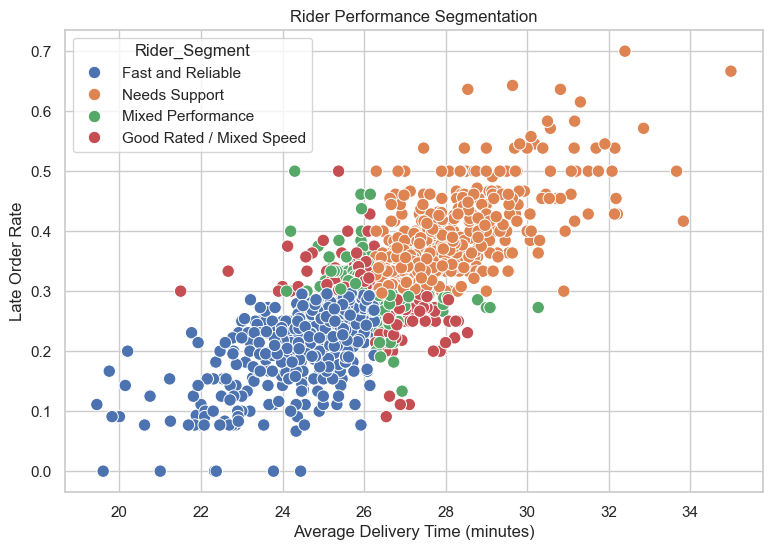

In [60]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=rider_profile,
    x="Average_Delivery_Time",
    y="Late_Rate",
    hue="Rider_Segment",
    s=80
)

plt.title("Rider Performance Segmentation")

plt.xlabel("Average Delivery Time (minutes)")

plt.ylabel("Late Order Rate")

plt.show()

### Problem Statement 8 – Model Selection, Explainability and Three Management Actions

In [61]:
print("Regression Model Comparison")

display(
    results_df.sort_values(
        by="MAE (minutes)"
    )
)

best_regression_model_name = results_df.iloc[0]["Model"]

print(
    "Best Regression Model:",
    best_regression_model_name
)

Regression Model Comparison


,Model,MAE (minutes),RMSE (minutes),R2 Score
2,Random Forest,3.229326,4.062938,0.811727
1,Decision Tree,3.364428,4.287079,0.790381
3,Gradient Boosting,3.702873,4.650523,0.753332
0,Linear Regression,4.888623,6.199769,0.561611


Best Regression Model: Random Forest


In [62]:
print("Classification Model Comparison")

display(
    classification_results.sort_values(
        by="PR-AUC",
        ascending=False
    )
)

print("Selected Classification Model:")
print(best_late_model_name)

print("Selected Threshold:")
print(best_threshold)

Classification Model Comparison


,Model,Accuracy,Precision,Recall,F1 Score,PR-AUC,ROC-AUC
2,Gradient Boosting,0.798004,0.745394,0.490628,0.591755,0.736141,0.851860
1,Random Forest,0.788025,0.698389,0.509739,0.589335,0.730254,0.840195
0,Logistic Regression,0.700296,0.498594,0.781698,0.608845,0.663630,0.807508


Selected Classification Model:
Gradient Boosting
Selected Threshold:
0.1


In [63]:
from sklearn.inspection import permutation_importance

importance_result = permutation_importance(
    final_classifier,
    X_test_late,
    y_test_late,
    scoring="average_precision",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test_late.columns,
    "Importance": importance_result.importances_mean
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

,Feature,Importance
9,Road_traffic_density,0.184602
8,Weatherconditions,0.165937
0,Distance_km,0.157329
12,Festival,0.059912
11,City,0.012781
7,Delivery_location_longitude,0.001804
3,Order_Month,0.000000
2,Order_Weekday,0.000000
1,Order_Hour,0.000000
10,Type_of_order,0.000000


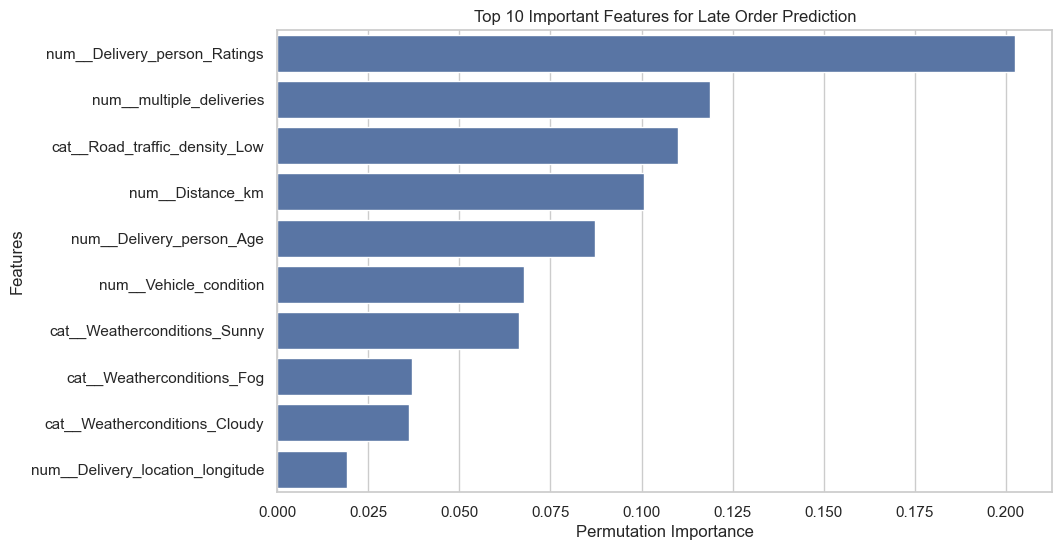

In [49]:
top_features = importance_df.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features for Late Order Prediction")

plt.xlabel("Permutation Importance")

plt.ylabel("Features")

plt.show()

In [57]:
traffic_summary = df_ps5.groupby(
    "Road_traffic_density"
).agg(
    Order_Count=("ID", "count"),

    Late_Orders=("Late_Order", "sum"),

    Late_Rate=("Late_Order", "mean")
).reset_index()

traffic_summary["Late_Rate_Percentage"] = (
    traffic_summary["Late_Rate"] * 100
)

display(
    traffic_summary.sort_values(
        by="Late_Rate",
        ascending=False
    )
)

,Road_traffic_density,Order_Count,Late_Orders,Late_Rate,Late_Rate_Percentage
1,Jam,14143,7162,0.506399,50.639893
0,High,4425,1485,0.335593,33.559322
3,Medium,10947,3555,0.324747,32.474651
4,Nan,601,186,0.309484,30.948419
2,Low,15477,1218,0.078697,7.869742


In [59]:

import pandas as pd

print("SEARCHING FOR AVAILABLE DATAFRAMES")
print("=" * 60)

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(f"\nDataFrame name: {name}")
        print("Shape:", obj.shape)
        print("Columns:", obj.columns.tolist())


SEARCHING FOR AVAILABLE DATAFRAMES

DataFrame name: _
Shape: (5, 5)
Columns: ['Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Distance_km']

DataFrame name: df
Shape: (45593, 21)
Columns: ['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)', 'Distance_km']

DataFrame name: df_eda
Shape: (45593, 20)
Columns: ['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density', '

In [62]:
import pandas as pd

print("AVAILABLE DATAFRAMES")
print("=" * 50)

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(f"\n{name}")
        print(obj.columns.tolist())

AVAILABLE DATAFRAMES

_
['Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Distance_km']

df
['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)', 'Distance_km']

df_eda
['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)']

_8
['Restaurant_latitu

In [64]:
import pandas as pd

print("AVAILABLE DATAFRAMES")
print("=" * 60)

for name, obj in globals().copy().items():
    if isinstance(obj, pd.DataFrame):
        print(f"\nDataFrame: {name}")
        print("Shape:", obj.shape)
        print("Columns:", obj.columns.tolist())

AVAILABLE DATAFRAMES

DataFrame: _
Shape: (5, 5)
Columns: ['Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Distance_km']

DataFrame: df
Shape: (45593, 21)
Columns: ['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)', 'Distance_km']

DataFrame: df_eda
Shape: (45593, 20)
Columns: ['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_

In [66]:
from pathlib import Path
import pandas as pd
import joblib

output_dir = Path("outputs")
output_dir.mkdir(parents=True, exist_ok=True)

results_to_save = {
    "classification_comparison.csv": "classification_results",
    "dark_store_zone_summary.csv": "zone_summary",
    "rider_segment_summary.csv": "rider_segment_summary",
    "classification_feature_importance.csv": "importance_df"
}

for filename, variable_name in results_to_save.items():
    obj = globals().get(variable_name)

    if isinstance(obj, pd.DataFrame):
        obj.to_csv(output_dir / filename, index=False)
        print(f"Saved: {filename}")
    else:
        print(f"MISSING: {variable_name} — summary must be created first.")

if "final_classifier" in globals():
    joblib.dump(
        final_classifier,
        output_dir / "final_late_order_classifier.joblib"
    )
    print("Saved: final_late_order_classifier.joblib")
else:
    print("MISSING: final_classifier")

print("\nSave process completed.")

Saved: classification_comparison.csv
MISSING: zone_summary — summary must be created first.
MISSING: rider_segment_summary — summary must be created first.
Saved: classification_feature_importance.csv
Saved: final_late_order_classifier.joblib

Save process completed.
